<a href="https://colab.research.google.com/github/petkuteliepa-del/DI-darbas/blob/main/lt_tree_full_workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 0: check the GPU

In [18]:
import torch
print('GPU available:', torch.cuda.is_available())
if not torch.cuda.is_available():
    print('No GPU. Runtime > Change runtime type > T4 GPU, then rerun from the top.')

GPU available: True


## Step 1: Google Drive, libraries and folder settings

In [19]:
!pip -q install open_clip_torch scikit-learn pandas matplotlib seaborn pillow tqdm joblib requests

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DATA_ROOT = Path('/content/drive/MyDrive/lt_trees')
MANIFEST  = DATA_ROOT / 'manifest.csv'
OUT_DIR   = DATA_ROOT / 'model_out'
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
print('Data folder:', DATA_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Data folder: /content/drive/MyDrive/lt_trees


# Part A: build the image dataset

## Step 2: write the download script
This cell saves the script as `gbif_download.py` in the Colab session. Run it once per session.

In [19]:
%%writefile gbif_download.py
#!/usr/bin/env python3
"""
Download training images for the Lithuanian tree identifier from GBIF
(iNaturalist research-grade observations), log licence + observer, and write
the manifest.csv expected by lt_tree_classifier_training.ipynb.

Stages (run in this order):
  count     how many licence-allowed images exist per species (quick, no download)
  download  download images and write/extend manifest.csv
  label     guess the organ (leaf/bark/whole_tree/fruit) for each image (zero-shot CLIP)
  review    make contact sheets so you can eyeball the organ labels

Example (Colab):
  !python gbif_download.py count    --out /content/drive/MyDrive/lt_trees
  !python gbif_download.py download --out /content/drive/MyDrive/lt_trees --target 800
  !python gbif_download.py label    --out /content/drive/MyDrive/lt_trees
  !python gbif_download.py review   --out /content/drive/MyDrive/lt_trees
"""
import argparse, io, random, re, time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

GBIF_API = "https://api.gbif.org/v1"
INAT_DATASET = "50c9509d-22c7-4a22-a47d-8c48425ef4a7"   # iNaturalist Research-grade Observations

SPECIES = [
    "Picea abies", "Pinus sylvestris", "Juniperus communis", "Taxus baccata", "Larix decidua",
    "Alnus glutinosa", "Alnus incana", "Betula pendula", "Betula pubescens",
    "Populus tremula", "Populus nigra", "Quercus robur", "Quercus petraea",
    "Carpinus betulus", "Tilia cordata", "Acer platanoides", "Fraxinus excelsior",
    "Fagus sylvatica", "Ulmus glabra", "Ulmus laevis", "Ulmus minor",
    "Salix alba", "Salix fragilis", "Salix caprea", "Sorbus aucuparia",
    "Malus sylvestris", "Pyrus pyraster", "Prunus padus",
]

# Search order: nearest first, then wider. Stops as soon as enough images are found.
GEOGRAPHIES = [
    {"country": "LT"}, {"country": "LV"}, {"country": "EE"}, {"country": "PL"},
    {"country": "FI"}, {"country": "SE"}, {"country": "DK"}, {"country": "DE"},
    {"continent": "EUROPE"},
]

# GBIF filter enum  ->  short name used in the manifest
LICENSES = {"CC0_1_0": "CC0", "CC_BY_4_0": "CC-BY", "CC_BY_NC_4_0": "CC-BY-NC"}

ORGANS = ["leaf", "bark", "whole_tree", "fruit"]
ORGAN_PROMPTS = {
    "leaf": ["a close-up photo of tree leaves", "a photo of a branch with leaves",
             "a photo of a single leaf", "a photo of conifer needles on a twig"],
    "bark": ["a close-up photo of tree bark", "the bark of a tree trunk",
             "a photo of rough bark texture"],
    "whole_tree": ["a photo of a whole tree", "a tree standing in a landscape",
                   "trees in a forest", "a photo of a tree crown"],
    "fruit": ["a photo of fruits on a tree", "a photo of tree seeds",
              "a photo of cones on a conifer", "a photo of acorns or nuts",
              "a photo of berries on a branch", "a photo of winged seeds"],
    "other": ["a photo of a flower", "a photo of tree catkins", "a photo of a person",
              "a photo of an insect or animal", "a photo of a mushroom or lichen",
              "a photo of a building or a road", "a screenshot or text"],
}


def slug(name): return name.lower().replace(" ", "_")


def norm_license(value):
    """Map a GBIF licence URL/string to CC0 / CC-BY / CC-BY-NC (or the raw value)."""
    v = (value or "").lower()
    if "publicdomain/zero" in v or v in ("cc0", "cc0_1_0"): return "CC0"
    if "licenses/by-nc" in v or "cc_by_nc" in v: return "CC-BY-NC"
    if "licenses/by/" in v or v in ("cc_by_4_0", "cc-by"): return "CC-BY"
    return value or ""


def rewrite_url(url, size):
    """iNaturalist open-data photos exist as small/medium/large/original; use a smaller one."""
    if "inaturalist" in url and size != "original":
        return re.sub(r"/(original|large|medium|small)\.(\w+)(\?.*)?$", rf"/{size}.\2", url)
    return url


def get_json(session, url, params, tries=4):
    for k in range(tries):
        try:
            r = session.get(url, params=params, timeout=60)
            r.raise_for_status()
            return r.json()
        except Exception:
            if k == tries - 1: raise
            time.sleep(2 ** k)


def match_taxon(session, name):
    d = get_json(session, f"{GBIF_API}/species/match", {"name": name, "rank": "species"})
    key = d.get("speciesKey") or d.get("usageKey")
    if not key or d.get("matchType") == "NONE":
        raise RuntimeError(f"GBIF could not match {name!r}")
    return key, d.get("scientificName", "?"), d.get("status", "?")


def search_params(key, geo, licenses, offset, limit):
    p = [("taxonKey", key), ("mediaType", "StillImage"), ("datasetKey", INAT_DATASET),
         ("occurrenceStatus", "PRESENT"), ("limit", limit), ("offset", offset)]
    p += [("license", l) for l in licenses]
    p += list(geo.items())
    return p


def count_images(session, key, geo, licenses):
    d = get_json(session, f"{GBIF_API}/occurrence/search", search_params(key, geo, licenses, 0, 0))
    return d["count"]


def fetch_candidates(session, key, licenses, want, max_per_obs, max_per_occ):
    allowed = {LICENSES[l] for l in licenses}
    seen, per_obs, cands = set(), Counter(), []
    for geo in GEOGRAPHIES:
        offset = 0
        while len(cands) < want and offset <= 99700:
            d = get_json(session, f"{GBIF_API}/occurrence/search",
                         search_params(key, geo, licenses, offset, 300))
            for occ in d.get("results", []):
                if occ["key"] in seen: continue
                seen.add(occ["key"])
                media = [m for m in occ.get("media", [])
                         if m.get("type") == "StillImage" and m.get("identifier")]
                for i, m in enumerate(media[:max_per_occ]):
                    lic = norm_license(m.get("license") or occ.get("license"))
                    if lic not in allowed: continue
                    obs = (occ.get("recordedBy") or m.get("creator")
                           or occ.get("rightsHolder") or "unknown").strip()
                    if per_obs[obs] >= max_per_obs: continue
                    per_obs[obs] += 1
                    cands.append({"gbif_id": occ["key"], "idx": i, "url": m["identifier"],
                                  "observer": obs, "license": lic,
                                  "country": occ.get("countryCode", ""),
                                  "date": (occ.get("eventDate") or "")[:10],
                                  "source": m.get("references") or occ.get("references") or ""})
            if d.get("endOfRecords"): break
            offset += 300
        if len(cands) >= want: break
    return cands[:want]


def download_one(c, species, out_dir, size, max_side):
    from PIL import Image
    import requests
    rel = Path("images") / slug(species) / f"{c['gbif_id']}_{c['idx']}.jpg"
    dest = out_dir / rel
    row = {"file": rel.as_posix(), "species": species, "organ": "unlabeled",
           "observer": c["observer"], "license": c["license"], "source_url": c["url"],
           "occurrence_page": c["source"], "gbif_id": c["gbif_id"],
           "country": c["country"], "date": c["date"]}
    if dest.exists(): return row
    dest.parent.mkdir(parents=True, exist_ok=True)
    url = rewrite_url(c["url"], size)
    for k in range(3):
        try:
            r = requests.get(url, timeout=60); r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)).convert("RGB")
            im.thumbnail((max_side, max_side))
            im.save(dest, "JPEG", quality=90)
            return row
        except Exception:
            time.sleep(2 ** k)
    return None


# ----------------------------------------------------------------- stages
def stage_count(a):
    import requests
    s = requests.Session()
    lic = list(LICENSES) if a.include_nc else ["CC0_1_0", "CC_BY_4_0"]
    print(f"{'species':<22}{'matched as':<34}{'LT':>6}{'Baltic+':>9}{'Europe':>9}")
    for sp in SPECIES:
        key, matched, status = match_taxon(s, sp)
        lt = count_images(s, key, {"country": "LT"}, lic)
        bal = lt + sum(count_images(s, key, {"country": c}, lic) for c in ("LV", "EE"))
        eu = count_images(s, key, {"continent": "EUROPE"}, lic)
        flag = "" if status == "ACCEPTED" else f"  [{status}]"
        print(f"{sp:<22}{matched[:32]:<34}{lt:>6}{bal:>9}{eu:>9}{flag}")
    print("\nCounts are occurrences with photos; most have 1-4 photos each.")


def stage_download(a):
    import pandas as pd, requests
    from tqdm.auto import tqdm
    out = Path(a.out); out.mkdir(parents=True, exist_ok=True)
    s = requests.Session()
    lic = list(LICENSES) if a.include_nc else ["CC0_1_0", "CC_BY_4_0"]
    man_path = out / "manifest.csv"
    old = pd.read_csv(man_path) if man_path.exists() else pd.DataFrame()
    species = [x for x in SPECIES if not a.only or x in a.only]
    new_rows = []
    for sp in species:
        have = int((old.species == sp).sum()) if len(old) else 0
        need = a.target - have
        if need <= 0:
            print(f"{sp}: already {have} images, skipping"); continue
        key, matched, status = match_taxon(s, sp)
        print(f"\n{sp}  (GBIF: {matched}, {status})  need {need}")
        cands = fetch_candidates(s, key, lic, int(need * 1.3), a.max_per_observer, a.max_per_obs_record)
        if len(old):   # skip what we already have
            have_files = set(old.file)
            cands = [c for c in cands if f"images/{slug(sp)}/{c['gbif_id']}_{c['idx']}.jpg" not in have_files]
        ok = 0
        with ThreadPoolExecutor(a.workers) as ex:
            futs = [ex.submit(download_one, c, sp, out, a.size, a.max_side) for c in cands]
            for f in tqdm(as_completed(futs), total=len(futs), desc=sp):
                r = f.result()
                if r: new_rows.append(r); ok += 1
        print(f"  downloaded {ok} / {len(cands)} candidates")
        # save after every species so a Colab disconnect loses little
        pd.concat([old, pd.DataFrame(new_rows)], ignore_index=True).drop_duplicates("file").to_csv(man_path, index=False)
    man = pd.read_csv(man_path)
    man[["file", "species", "observer", "license", "source_url", "occurrence_page"]].to_csv(out / "ATTRIBUTION.csv", index=False)
    print(f"\nManifest: {man_path}  ({len(man)} images)")
    print("Images per species:\n", man.species.value_counts().to_string())
    print("\nNext: run the 'label' stage to fill in the organ column.")


def stage_label(a):
    import pandas as pd, torch, open_clip
    from PIL import Image
    from tqdm.auto import tqdm
    out = Path(a.out); man_path = out / "manifest.csv"
    df = pd.read_csv(man_path)
    if "organ_conf" not in df: df["organ_conf"] = float("nan")
    todo = df.index[df.organ_conf.isna()].tolist()
    print(len(todo), "images to label")
    if not todo: return
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    model, _, pre = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
    tok = open_clip.get_tokenizer("ViT-B-32")
    model = model.to(dev).eval()
    names = ORGANS + ["other"]
    with torch.no_grad():
        T = []
        for n in names:
            t = model.encode_text(tok(ORGAN_PROMPTS[n]).to(dev))
            t = torch.nn.functional.normalize(t.float(), dim=-1).mean(0)
            T.append(torch.nn.functional.normalize(t, dim=0))
        T = torch.stack(T)
    for i in tqdm(range(0, len(todo), a.batch)):
        idx = todo[i:i + a.batch]
        ims, keep = [], []
        for j in idx:
            try:
                ims.append(pre(Image.open(out / df.at[j, "file"]).convert("RGB"))); keep.append(j)
            except Exception:
                df.at[j, "organ"] = "unlabeled"; df.at[j, "organ_conf"] = 0.0
        if not ims: continue
        with torch.no_grad():
            f = torch.nn.functional.normalize(model.encode_image(torch.stack(ims).to(dev)).float(), dim=-1)
            p = (100.0 * f @ T.T).softmax(-1).cpu()
        for j, row in zip(keep, p):
            k = int(row.argmax()); conf = float(row[k])
            df.at[j, "organ_conf"] = conf
            df.at[j, "organ"] = names[k] if (names[k] != "other" and conf >= a.min_conf) else "unlabeled"
        if (i // a.batch) % 20 == 0: df.to_csv(man_path, index=False)
    df.to_csv(man_path, index=False)
    print(df.pivot_table(index="species", columns="organ", values="file", aggfunc="count", fill_value=0))
    print("\n'unlabeled' rows are ignored by the training notebook. Run 'review' to check the labels.")


def stage_review(a):
    import pandas as pd
    from PIL import Image
    out = Path(a.out); df = pd.read_csv(out / "manifest.csv")
    (out / "review").mkdir(exist_ok=True)
    rnd = random.Random(0); th, cols = 160, 8
    for organ in ORGANS + ["unlabeled"]:
        sub = df[df.organ == organ]
        if sub.empty: continue
        pick = sub.sample(min(a.n, len(sub)), random_state=0)
        rows = (len(pick) + cols - 1) // cols
        sheet = Image.new("RGB", (cols * th, rows * th), "white")
        for k, f in enumerate(pick.file):
            try:
                im = Image.open(out / f).convert("RGB"); im.thumbnail((th, th))
                sheet.paste(im, ((k % cols) * th, (k // cols) * th))
            except Exception: pass
        sheet.save(out / "review" / f"{organ}.jpg", quality=85)
        print(f"wrote review/{organ}.jpg  ({len(pick)} random images labelled '{organ}')")


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("stage", choices=["count", "download", "label", "review"])
    ap.add_argument("--out", required=True, help="dataset folder (e.g. on Google Drive)")
    ap.add_argument("--target", type=int, default=800, help="images wanted per species")
    ap.add_argument("--only", nargs="*", help="restrict to these Latin names")
    ap.add_argument("--include-nc", action="store_true", help="also allow CC-BY-NC images")
    ap.add_argument("--max-per-observer", type=int, default=25, help="cap per observer per species")
    ap.add_argument("--max-per-obs-record", type=int, default=3, help="max photos from one observation")
    ap.add_argument("--size", default="medium", choices=["small", "medium", "large", "original"])
    ap.add_argument("--max-side", type=int, default=768)
    ap.add_argument("--workers", type=int, default=8)
    ap.add_argument("--batch", type=int, default=64)
    ap.add_argument("--min-conf", type=float, default=0.5, help="organ label confidence cut-off")
    ap.add_argument("--n", type=int, default=48, help="images per review sheet")
    a = ap.parse_args()
    {"count": stage_count, "download": stage_download, "label": stage_label, "review": stage_review}[a.stage](a)


if __name__ == "__main__":
    main()


Overwriting gbif_download.py


## Step 3: count the available images
Shows how many licence-allowed photos exist per species (Lithuania / Baltic / all Europe). Nothing is downloaded. Check the "matched as" column for wrong names. Species with under about 300 in Europe will be weak.

## **extra step - 7 pamestos rūšys**

In [28]:
import re
p = '/content/gbif_download.py'
s = open(p).read()
new = '''def match_taxon(session, name):
    d = get_json(session, f"{GBIF_API}/species/match", {"name": name, "rank": "species", "verbose": "true"})
    key = d.get("speciesKey") or d.get("usageKey")
    if key and d.get("matchType") != "NONE":
        return key, d.get("scientificName", "?"), d.get("status", "?")
    for alt in d.get("alternatives", []):
        if (alt.get("rank") == "SPECIES" and alt.get("status") == "ACCEPTED"
                and alt.get("canonicalName") == name):
            return alt.get("speciesKey") or alt["usageKey"], alt.get("scientificName", "?"), "ACCEPTED"
    r = get_json(session, f"{GBIF_API}/species/search",
                 {"q": name, "rank": "SPECIES", "status": "ACCEPTED", "limit": 20,
                  "datasetKey": "d7dddbf4-2cf0-4f39-9b2a-bb099caae36c"})
    for x in r.get("results", []):
        if x.get("canonicalName") == name:
            return x.get("speciesKey") or x["key"], x.get("scientificName", "?"), x.get("taxonomicStatus", "ACCEPTED")
    raise RuntimeError(f"GBIF could not match {name!r}")


'''
s, n = re.subn(r"def match_taxon\(session, name\):.*?(?=def search_params)", lambda m: new, s, flags=re.S)
print("patched" if n == 1 else "NOT FOUND, tell me")
open(p, 'w').write(s)

patched


15468

In [29]:
!python gbif_download.py download --out {DATA_ROOT} --target 800 --only "Salix alba" "Salix fragilis" "Salix caprea" "Sorbus aucuparia" "Malus sylvestris" "Pyrus pyraster" "Prunus padus"


Salix alba  (GBIF: Salix alba (Crawford, 1914) Crawford, 1914, ACCEPTED)  need 800
Salix alba: 0it [00:00, ?it/s]
  downloaded 0 / 0 candidates

Salix fragilis  (GBIF: Salix fragilis L., ACCEPTED)  need 800
Salix fragilis: 100% 387/387 [01:01<00:00,  6.33it/s]
  downloaded 387 / 387 candidates

Salix caprea  (GBIF: Salix caprea L., ACCEPTED)  need 800
Salix caprea: 100% 1040/1040 [02:44<00:00,  6.33it/s]
  downloaded 1040 / 1040 candidates

Sorbus aucuparia  (GBIF: Sorbus aucuparia L., ACCEPTED)  need 800
Sorbus aucuparia: 100% 1040/1040 [02:53<00:00,  5.99it/s]
  downloaded 1040 / 1040 candidates

Malus sylvestris  (GBIF: Malus sylvestris Mill., ACCEPTED)  need 800
Malus sylvestris: 100% 460/460 [01:13<00:00,  6.26it/s]
  downloaded 460 / 460 candidates

Pyrus pyraster  (GBIF: Pyrus pyraster (L.) Burgsd., ACCEPTED)  need 800
Pyrus pyraster: 0it [00:00, ?it/s]
  downloaded 0 / 0 candidates

Prunus padus  (GBIF: Prunus padus L., ACCEPTED)  need 800
Prunus padus: 100% 1040/1040 [02:48<0

In [30]:
import re
p = '/content/gbif_download.py'
s = open(p).read()
new = '''def match_taxon(session, name):
    d = get_json(session, f"{GBIF_API}/species/match",
                 {"name": name, "rank": "species", "kingdom": "Plantae", "verbose": "true"})
    key = d.get("speciesKey") or d.get("usageKey")
    if key and d.get("matchType") != "NONE" and d.get("kingdom") == "Plantae":
        return key, d.get("scientificName", "?"), d.get("status", "?")
    for alt in d.get("alternatives", []):
        if (alt.get("rank") == "SPECIES" and alt.get("status") == "ACCEPTED"
                and alt.get("kingdom") == "Plantae" and alt.get("canonicalName") == name):
            return alt.get("speciesKey") or alt["usageKey"], alt.get("scientificName", "?"), "ACCEPTED"
    r = get_json(session, f"{GBIF_API}/species/search",
                 {"q": name, "rank": "SPECIES", "status": "ACCEPTED", "limit": 50,
                  "highertaxonKey": 6, "datasetKey": "d7dddbf4-2cf0-4f39-9b2a-bb099caae36c"})
    for x in r.get("results", []):
        if x.get("canonicalName") == name and x.get("kingdom") == "Plantae":
            return x.get("speciesKey") or x["key"], x.get("scientificName", "?"), x.get("taxonomicStatus", "ACCEPTED")
    raise RuntimeError(f"GBIF could not match {name!r} as a plant")


'''
s, n = re.subn(r"def match_taxon\(session, name\):.*?(?=def search_params)", lambda m: new, s, flags=re.S)
print("patched" if n == 1 else "NOT FOUND, tell me")
open(p, 'w').write(s)

patched


15643

In [33]:
!python gbif_download.py download --out {DATA_ROOT} --target 800 --only "Salix alba" "Salix fragilis" "Salix caprea" "Sorbus aucuparia" "Malus sylvestris" "Pyrus pyraster" "Prunus padus"

Salix alba: already 1040 images, skipping

Salix fragilis  (GBIF: Salix fragilis L., ACCEPTED)  need 413
Salix fragilis: 0it [00:00, ?it/s]
  downloaded 0 / 0 candidates
Salix caprea: already 1040 images, skipping
Sorbus aucuparia: already 1040 images, skipping

Malus sylvestris  (GBIF: Malus sylvestris Mill., ACCEPTED)  need 340
Malus sylvestris: 0it [00:00, ?it/s]
  downloaded 0 / 0 candidates

Pyrus pyraster  (GBIF: Pyrus pyraster (L.) Burgsd., ACCEPTED)  need 800
Pyrus pyraster: 0it [00:00, ?it/s]
  downloaded 0 / 0 candidates
Prunus padus: already 1040 images, skipping

Manifest: /content/drive/MyDrive/lt_trees/manifest.csv  (26677 images)
Images per species:
 species
Pinus sylvestris      1040
Taxus baccata         1040
Juniperus communis    1040
Alnus incana          1040
Betula pubescens      1040
Larix decidua         1040
Alnus glutinosa       1040
Populus tremula       1040
Populus nigra         1040
Quercus petraea       1040
Quercus robur         1040
Ulmus laevis         

In [34]:
import sys, requests
sys.path.insert(0, '/content')
import gbif_download as g
s = requests.Session()

def n(key, lic, inat=True):
    p = [("taxonKey", key), ("mediaType", "StillImage"), ("occurrenceStatus", "PRESENT"),
         ("limit", 0), ("continent", "EUROPE")]
    if inat: p.append(("datasetKey", g.INAT_DATASET))
    p += [("license", l) for l in lic]
    return s.get(f"{g.GBIF_API}/occurrence/search", params=p, timeout=60).json()["count"]

for sp in ["Salix fragilis", "Malus sylvestris", "Pyrus pyraster"]:
    key = g.match_taxon(s, sp)[0]
    print(sp, key)
    print("  iNat, CC0/CC-BY        :", n(key, ["CC0_1_0", "CC_BY_4_0"]))
    print("  iNat, plus CC-BY-NC    :", n(key, ["CC0_1_0", "CC_BY_4_0", "CC_BY_NC_4_0"]))
    print("  all datasets, any licence:", n(key, []))

Salix fragilis 5372829
  iNat, CC0/CC-BY        : 319
  iNat, plus CC-BY-NC    : 1006
  all datasets, any licence: 1006
Malus sylvestris 3001509
  iNat, CC0/CC-BY        : 302
  iNat, plus CC-BY-NC    : 1492
  all datasets, any licence: 1492
Pyrus pyraster 5362445
  iNat, CC0/CC-BY        : 0
  iNat, plus CC-BY-NC    : 0
  all datasets, any licence: 0


In [4]:
!python gbif_download.py count --out {DATA_ROOT}

species               matched as                            LT  Baltic+   Europe
Picea abies           Picea abies (L.) H.Karst.            151      664     5832
Pinus sylvestris      Pinus sylvestris L.                  184      642     9977
Juniperus communis    Juniperus communis L.                 53      113     5078
Taxus baccata         Taxus baccata L.                       2        4     5115
Larix decidua         Larix decidua Mill.                    0        1     1633
Alnus glutinosa       Alnus glutinosa (L.) Gaertn.          32       68     7871
Alnus incana          Alnus incana (L.) Moench              16       26     1568
Betula pendula        Betula pendula Roth                   15       27     5345
Betula pubescens      Betula pubescens Ehrh.                 6        9     1537
Populus tremula       Populus tremula L.                    50       64     4652
Populus nigra         Populus nigra L.                       0        1     1124
Quercus robur         Quercu

## Step 4: small test download
Downloads 50 images each for two species, to check that everything works. Afterwards, look in Drive: `lt_trees/images/` should contain JPEGs and `manifest.csv` should exist.

In [5]:
!python gbif_download.py download --out {DATA_ROOT} --target 50 --only "Picea abies" "Betula pendula"


Picea abies  (GBIF: Picea abies (L.) H.Karst., ACCEPTED)  need 50
Picea abies: 100% 65/65 [00:11<00:00,  5.65it/s]
  downloaded 65 / 65 candidates

Betula pendula  (GBIF: Betula pendula Roth, ACCEPTED)  need 50
Betula pendula: 100% 65/65 [00:10<00:00,  6.23it/s]
  downloaded 65 / 65 candidates

Manifest: /content/drive/MyDrive/lt_trees/manifest.csv  (130 images)
Images per species:
 species
Picea abies       65
Betula pendula    65

Next: run the 'label' stage to fill in the organ column.


## Step 5: full download
Downloads up to 800 images per species. Takes roughly 30-90 minutes: keep the tab open. If it stops, rerun this cell and it continues.

In [6]:
..!python gbif_download.py download --out {DATA_ROOT} --target 800


Picea abies  (GBIF: Picea abies (L.) H.Karst., ACCEPTED)  need 735
Picea abies: 100% 890/890 [02:26<00:00,  6.08it/s]
  downloaded 890 / 890 candidates

Pinus sylvestris  (GBIF: Pinus sylvestris L., ACCEPTED)  need 800
Pinus sylvestris: 100% 1040/1040 [02:50<00:00,  6.08it/s]
  downloaded 1040 / 1040 candidates

Juniperus communis  (GBIF: Juniperus communis L., ACCEPTED)  need 800
Juniperus communis: 100% 1040/1040 [02:55<00:00,  5.92it/s]
  downloaded 1040 / 1040 candidates

Taxus baccata  (GBIF: Taxus baccata L., ACCEPTED)  need 800
Taxus baccata: 100% 1040/1040 [02:51<00:00,  6.08it/s]
  downloaded 1040 / 1040 candidates

Larix decidua  (GBIF: Larix decidua Mill., ACCEPTED)  need 800
Larix decidua: 100% 1040/1040 [02:47<00:00,  6.19it/s]
  downloaded 1040 / 1040 candidates

Alnus glutinosa  (GBIF: Alnus glutinosa (L.) Gaertn., ACCEPTED)  need 800
Alnus glutinosa: 100% 1040/1040 [02:48<00:00,  6.17it/s]
  downloaded 1040 / 1040 candidates

Alnus incana  (GBIF: Alnus incana (L.) Moen

## Step 6: label the organs
Guesses whether each photo shows a leaf, bark, the whole tree or fruit/seed. Photos it is unsure about (and flowers, people, insects) are marked `unlabeled` and are ignored in training.

In [36]:
!python gbif_download.py label --out {DATA_ROOT}

5007 images to label
/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(
100% 79/79 [01:00<00:00,  1.30it/s]
organ               bark  fruit  leaf  unlabeled  whole_tree
species                                                     
Acer platanoides      19    131   761         81          48
Alnus glutinosa       32    362   424        124          98
Alnus incana          16    309   572        101          42
Betula pendula        82    111   319        167         276
Betula pubescens      43    119   642        126         110
Carpinus betulus      38    193   616         80         113
Fagus sylvatica       16    129   659         81         155
Fraxinus excelsior    17    269   521        147          86
Juniperus communis     8    437   134        227         234
Larix decidua         15    404   223        153         245
Mal

## Step 7: review the labels
Creates sheets of random images per organ. **Check them.** `leaf` should mostly show leaves, `bark` mostly bark, and so on. If a sheet is clearly wrong, tell me before training.

wrote review/leaf.jpg  (48 random images labelled 'leaf')
wrote review/bark.jpg  (48 random images labelled 'bark')
wrote review/whole_tree.jpg  (48 random images labelled 'whole_tree')
wrote review/fruit.jpg  (48 random images labelled 'fruit')
wrote review/unlabeled.jpg  (48 random images labelled 'unlabeled')
leaf


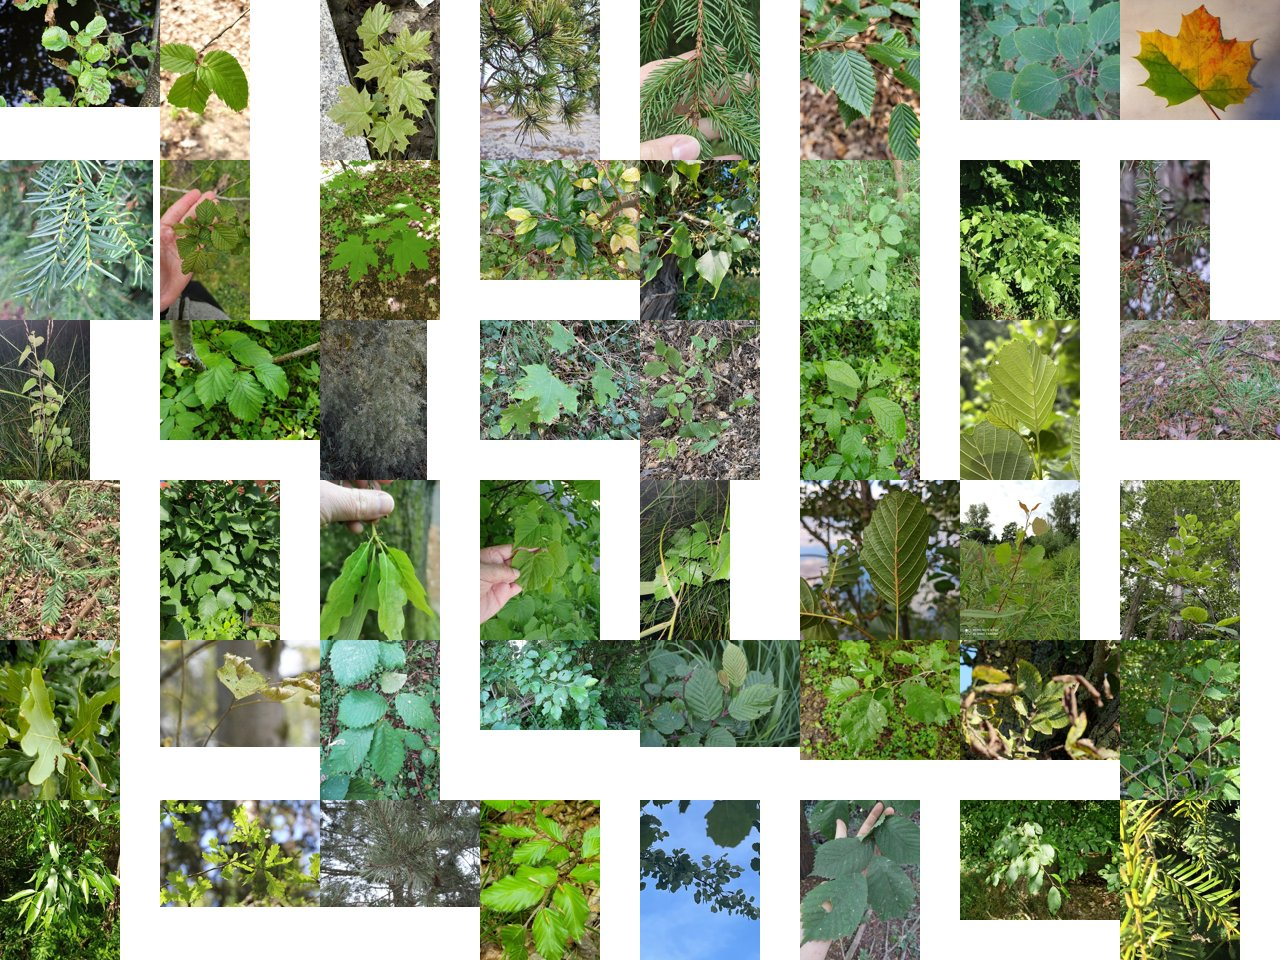

bark


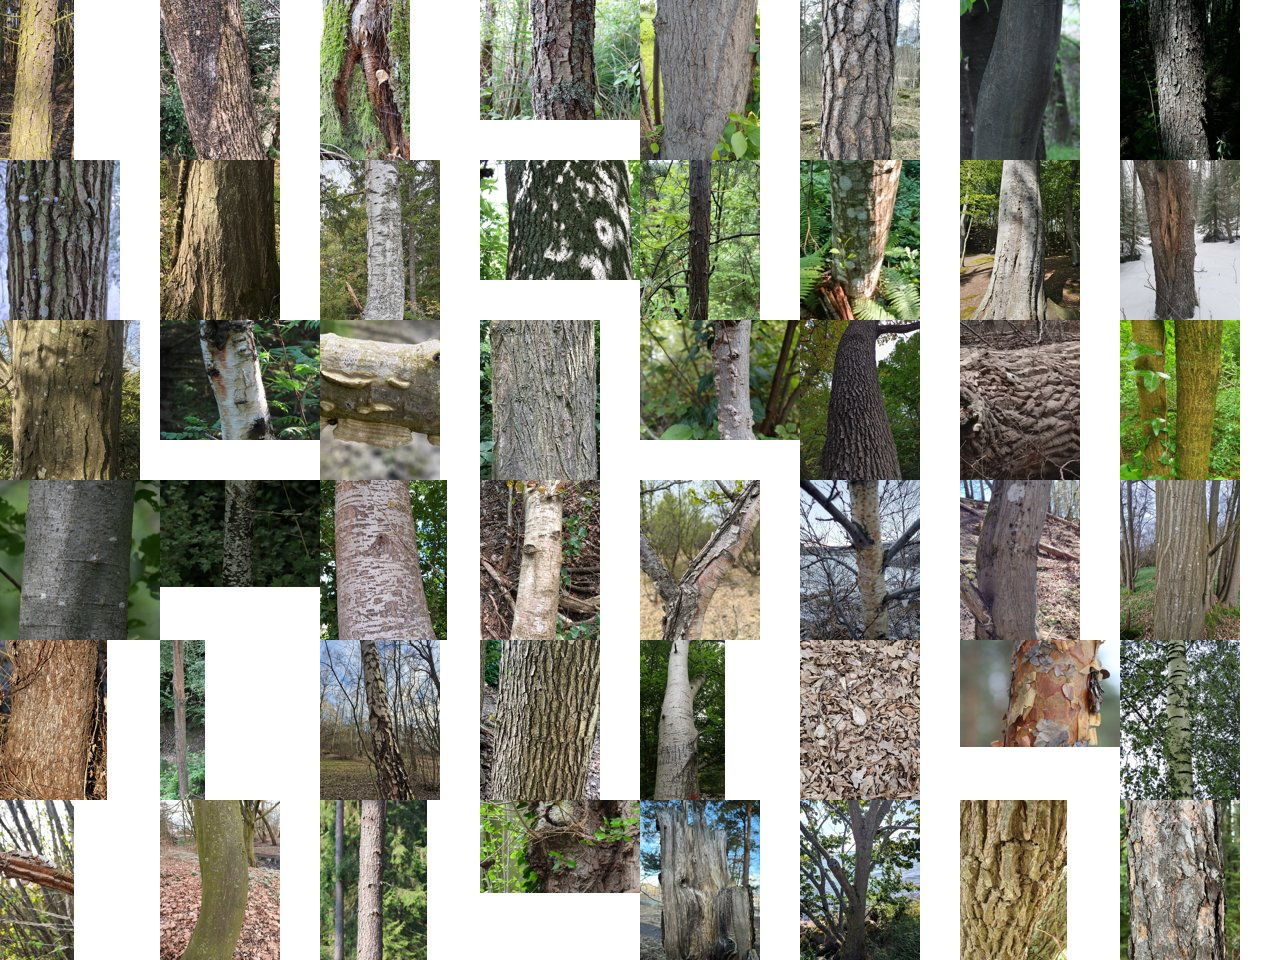

whole_tree


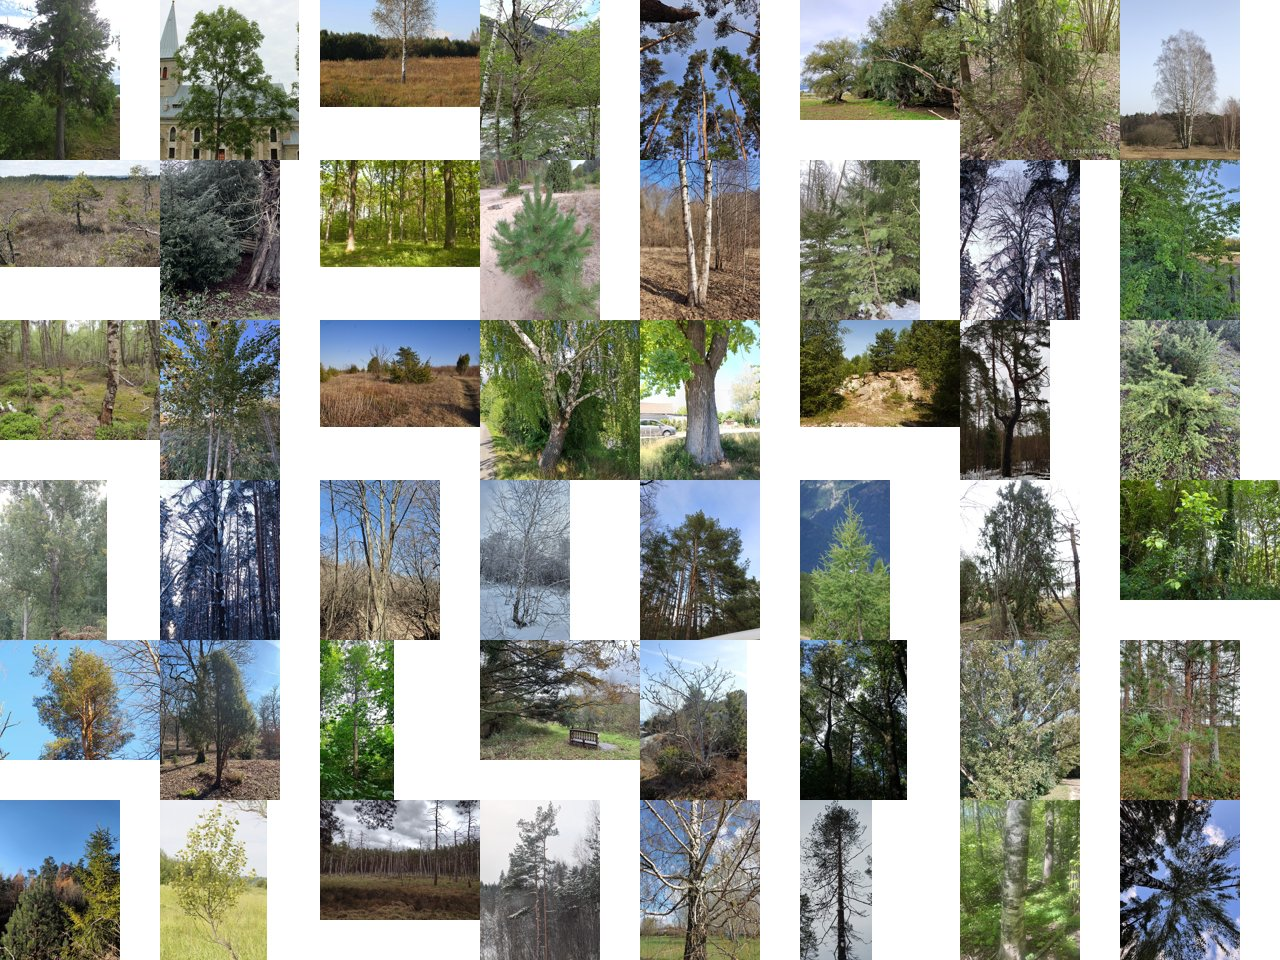

fruit


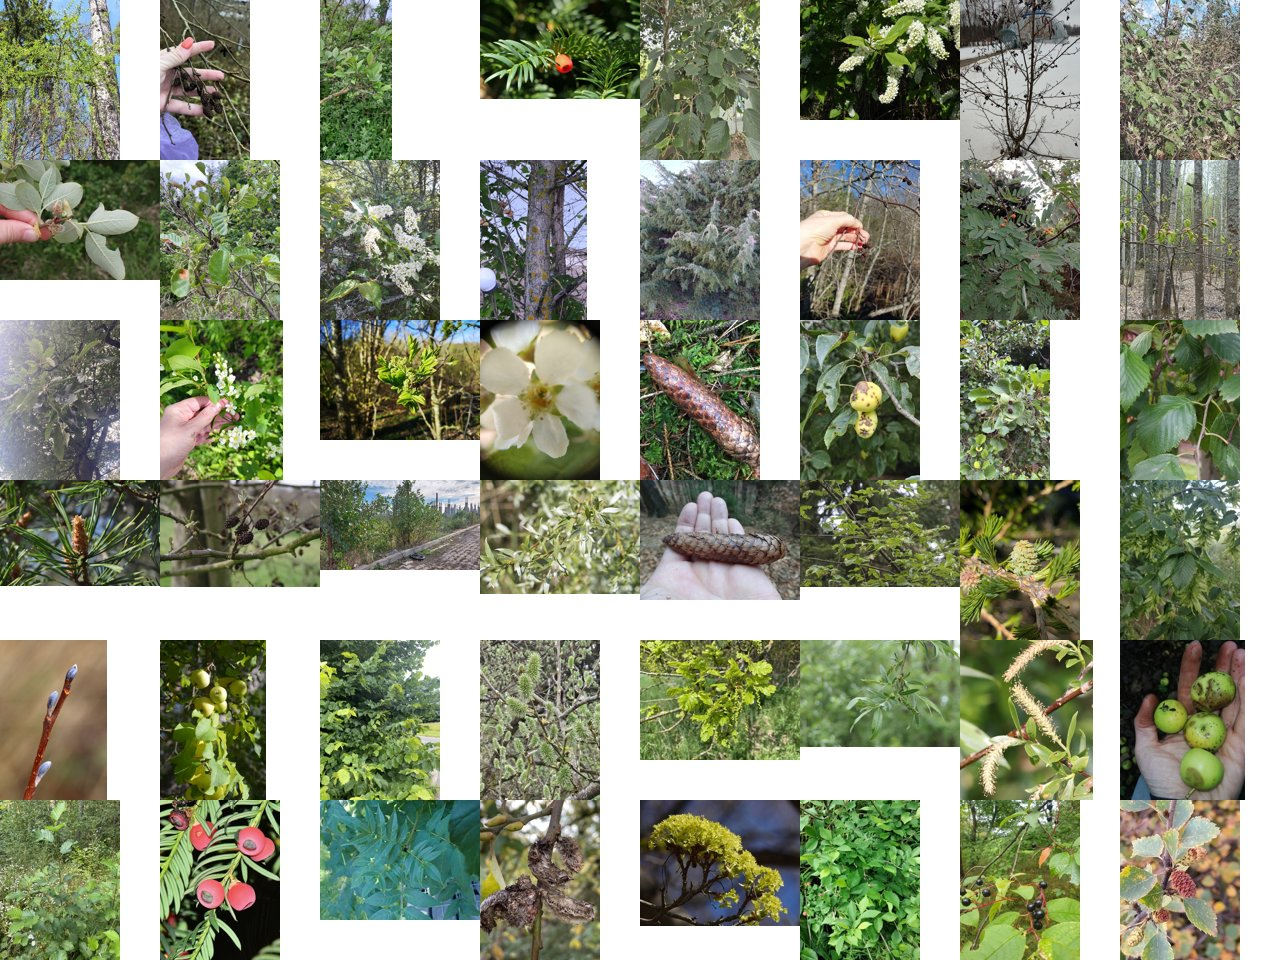

unlabeled


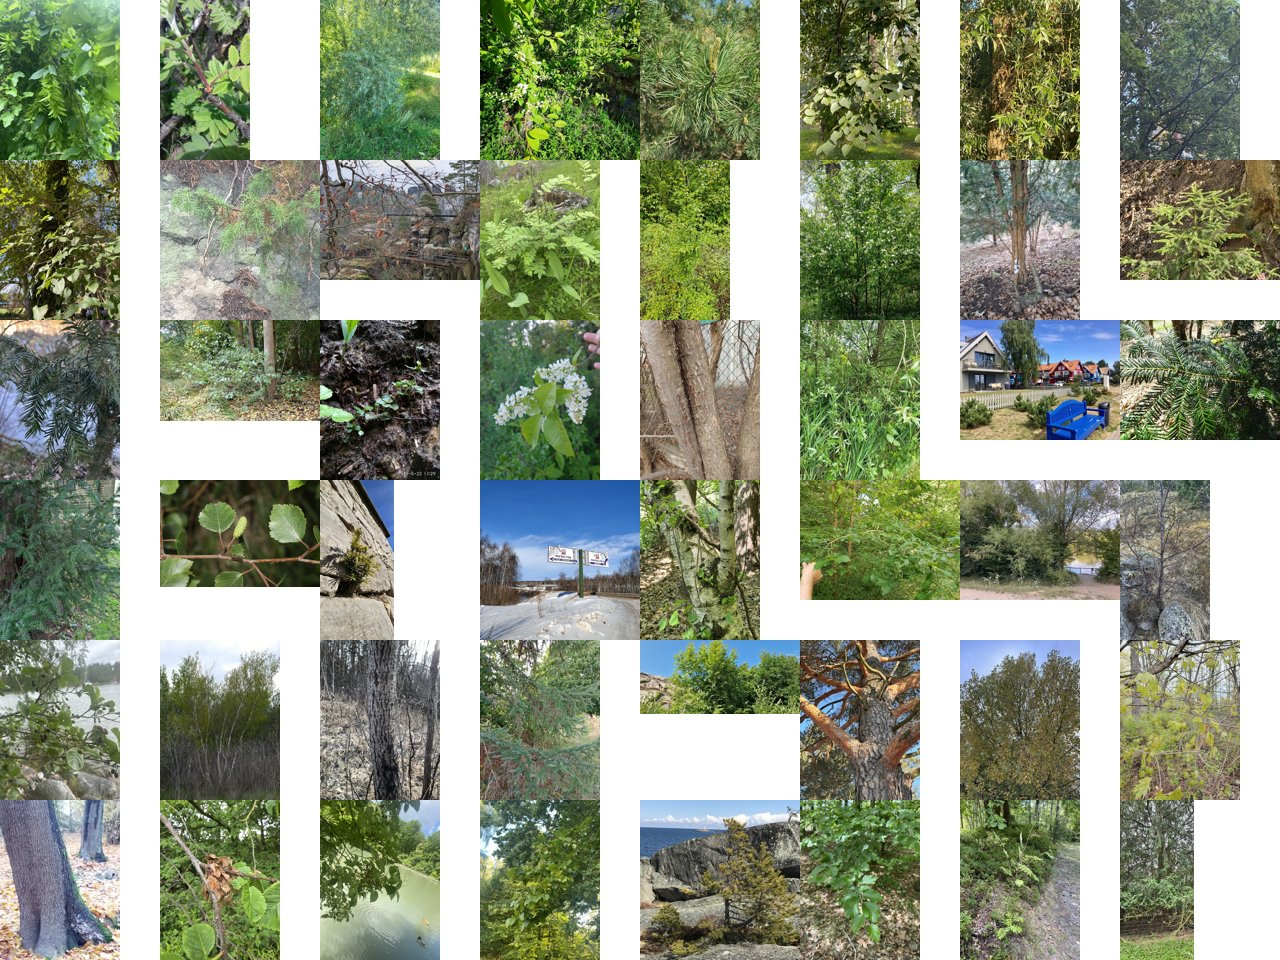

In [37]:
!python gbif_download.py review --out {DATA_ROOT}

from IPython.display import Image, display
for o in ['leaf', 'bark', 'whole_tree', 'fruit', 'unlabeled']:
    f = DATA_ROOT / 'review' / f'{o}.jpg'
    if f.exists():
        print(o); display(Image(filename=str(f)))

**Before continuing, check the table printed by step 6.** If bark or fruit counts are very low for many species, the model will be weak on those organs. You can still train, and the results will show how weak.

---
# Part B: train the model
Everything below needs the manifest and labelled images from Part A.

## 1. Locked species list (28)

In [38]:
SPECIES = {
 'Picea abies': 'Paprastoji eglė',
 'Pinus sylvestris': 'Paprastoji pušis',
 'Juniperus communis': 'Paprastasis kadagys',
 'Taxus baccata': 'Europinis kukmedis',
 'Larix decidua': 'Europinis maumedis',
 'Alnus glutinosa': 'Juodalksnis',
 'Alnus incana': 'Baltalksnis',
 'Betula pendula': 'Karpotasis beržas',
 'Betula pubescens': 'Plaukuotasis beržas',
 'Populus tremula': 'Drebulė',
 'Populus nigra': 'Juodoji tuopa',
 'Quercus robur': 'Paprastasis ąžuolas',
 'Quercus petraea': 'Bekotis ąžuolas',
 'Carpinus betulus': 'Paprastasis skroblas',
 'Tilia cordata': 'Mažalapė liepa',
 'Acer platanoides': 'Paprastasis klevas',
 'Fraxinus excelsior': 'Paprastasis uosis',
 'Fagus sylvatica': 'Paprastasis bukas',
 'Ulmus glabra': 'Kalninė guoba',
 'Ulmus laevis': 'Paprastoji vinkšna',
 'Ulmus minor': 'Paprastasis skirpstas',
 'Salix alba': 'Baltasis gluosnis',
 'Salix fragilis': 'Trapusis gluosnis',
 'Salix caprea': 'Blindė',
 'Sorbus aucuparia': 'Paprastasis šermukšnis',
 'Malus sylvestris': 'Miškinė obelis',
 'Pyrus pyraster': 'Miškinė kriaušė',
 'Prunus padus': 'Paprastoji ieva',
}
ORGANS = ['leaf', 'bark', 'whole_tree', 'fruit']
CLASSES = sorted(SPECIES)                      # fixed class order
cls2idx = {c: i for i, c in enumerate(CLASSES)}
genus_of = {c: c.split()[0] for c in CLASSES}
print(len(CLASSES), 'species')

28 species


## 2. Load and validate the manifest

In [39]:
import pandas as pd
df = pd.read_csv(MANIFEST)
need = {'file', 'species', 'organ', 'observer'}
assert need <= set(df.columns), f'manifest missing columns: {need - set(df.columns)}'

bad_sp = set(df.species) - set(CLASSES)
bad_org = set(df.organ) - set(ORGANS)
if bad_sp:  print('Unknown species (dropped):', bad_sp)
if bad_org: print('Unknown organs (dropped):', bad_org)
df = df[df.species.isin(CLASSES) & df.organ.isin(ORGANS)].copy()
df['observer'] = df['observer'].fillna('unknown').astype(str)
df['path'] = df['file'].apply(lambda f: str(DATA_ROOT / f))
df['y'] = df.species.map(cls2idx)
df['y_organ'] = df.organ.map({o: i for i, o in enumerate(ORGANS)})

missing = [p for p in df.path if not Path(p).exists()]
print('missing files:', len(missing))
df = df[df.path.map(lambda p: Path(p).exists())].reset_index(drop=True)

print(len(df), 'images')
display(df.pivot_table(index='species', columns='organ', values='file', aggfunc='count', fill_value=0))

Unknown organs (dropped): {'unlabeled'}
missing files: 0
23545 images


organ,bark,fruit,leaf,whole_tree
species,,,,
Acer platanoides,19,131,761,48
Alnus glutinosa,32,362,424,98
Alnus incana,16,309,572,42
Betula pendula,82,111,319,276
Betula pubescens,43,119,642,110
Carpinus betulus,38,193,616,113
Fagus sylvatica,16,129,659,155
Fraxinus excelsior,17,269,521,86
Juniperus communis,8,437,134,234


**Check the table above.** Species with fewer than about 100 images in total, or organs with fewer than about 30 per species, will be weak. Collect more for those before trusting the results.

## 3. Feature extraction with BioCLIP

In [40]:
import torch, numpy as np, open_clip
from PIL import Image
from tqdm.auto import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
model, _, preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip')
model = model.to(device).eval()

class DS(torch.utils.data.Dataset):
    def __init__(self, paths, flip=False): self.paths, self.flip = paths, flip
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            im = Image.open(self.paths[i]).convert('RGB')
        except Exception:
            im = Image.new('RGB', (224, 224))      # unreadable file -> blank (flagged below)
            return preprocess(im), 0
        if self.flip: im = im.transpose(Image.FLIP_LEFT_RIGHT)
        return preprocess(im), 1

@torch.no_grad()
def embed(paths, flip=False, bs=64):
    dl = torch.utils.data.DataLoader(DS(paths, flip), batch_size=bs, num_workers=2)
    feats, ok = [], []
    for x, o in tqdm(dl):
        with torch.autocast(device, enabled=(device == 'cuda')):
            f = model.encode_image(x.to(device))
        feats.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu()); ok.append(o)
    return torch.cat(feats).numpy(), torch.cat(ok).numpy().astype(bool)

CACHE = OUT_DIR / 'features.npz'
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=True)
    if list(z['paths']) == list(df.path):
        X, X_flip, ok = z['X'], z['X_flip'], z['ok']
        print('loaded cached features')
    else:
        CACHE.unlink()
if not CACHE.exists():
    X, ok = embed(list(df.path))
    X_flip, _ = embed(list(df.path), flip=True)     # flipped copy = cheap augmentation for training
    np.savez(CACHE, X=X, X_flip=X_flip, ok=ok, paths=np.array(df.path))

print('unreadable images:', (~ok).sum())
df, X, X_flip = df[ok].reset_index(drop=True), X[ok], X_flip[ok]

device: cuda


  0%|          | 0/368 [00:00<?, ?it/s]

  0%|          | 0/368 [00:00<?, ?it/s]

unreadable images: 0


## 4. Split by observer
Train/val/test are split by **observer**, so the same person's near-duplicate photos never land in both train and test. This gives a more honest accuracy than a random split.

In [42]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss.split(X, df.y, groups=df.observer))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X[trainval_idx], df.y.iloc[trainval_idx], groups=df.observer.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]

print('train/val/test:', len(train_idx), len(val_idx), len(test_idx))
for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    n = df.y.iloc[idx].nunique()
    print(f'{name}: {n}/{len(CLASSES)} species present')

train/val/test: 16489 3239 3817
train: 27/28 species present
val: 27/28 species present
test: 27/28 species present


If a species is missing from val or test, it has too few distinct observers. Add more images from more observers for it.

## 5. Train the classifiers

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y = df.y.values
Xtr = np.concatenate([X[train_idx], X_flip[train_idx]])
ytr = np.concatenate([y[train_idx], y[train_idx]])

best = None
for C in [1, 3, 10, 30, 100]:
    clf = LogisticRegression(C=C, max_iter=2000, class_weight='balanced')
    clf.fit(Xtr, ytr)
    acc = accuracy_score(y[val_idx], clf.predict(X[val_idx]))
    print(f'C={C:<4} val acc={acc:.3f}')
    if best is None or acc > best[0]: best = (acc, C, clf)
val_acc, bestC, species_clf = best
print('best C:', bestC)

# organ classifier (used by the app to say "this looks like a bark photo")
yo = df.y_organ.values
organ_clf = LogisticRegression(C=10, max_iter=2000, class_weight='balanced')
organ_clf.fit(np.concatenate([X[train_idx], X_flip[train_idx]]), np.concatenate([yo[train_idx]] * 2))
print('organ acc (test):', accuracy_score(yo[test_idx], organ_clf.predict(X[test_idx])))

NameError: name 'df' is not defined

## 6. Evaluate on the held-out test set

TEST top-1: 0.803   top-3: 0.933

Accuracy per organ:
  leaf        n=1968  top-1=0.861
  bark        n=127   top-1=0.472
  whole_tree  n=704   top-1=0.628
  fruit       n=1018  top-1=0.855

Per-species:
                    precision    recall  f1-score   support

  Acer platanoides       0.94      0.80      0.87       193
   Alnus glutinosa       0.77      0.81      0.79       179
      Alnus incana       0.80      0.77      0.78       151
    Betula pendula       0.66      0.69      0.68       134
  Betula pubescens       0.72      0.69      0.71       148
  Carpinus betulus       0.70      0.79      0.75       131
   Fagus sylvatica       0.79      0.79      0.79       132
Fraxinus excelsior       0.79      0.91      0.85       163
Juniperus communis       0.96      0.94      0.95       145
     Larix decidua       0.79      0.91      0.84       113
  Malus sylvestris       0.80      0.90      0.85        50
       Picea abies       0.90      0.79      0.84       165
  Pinus sylvest

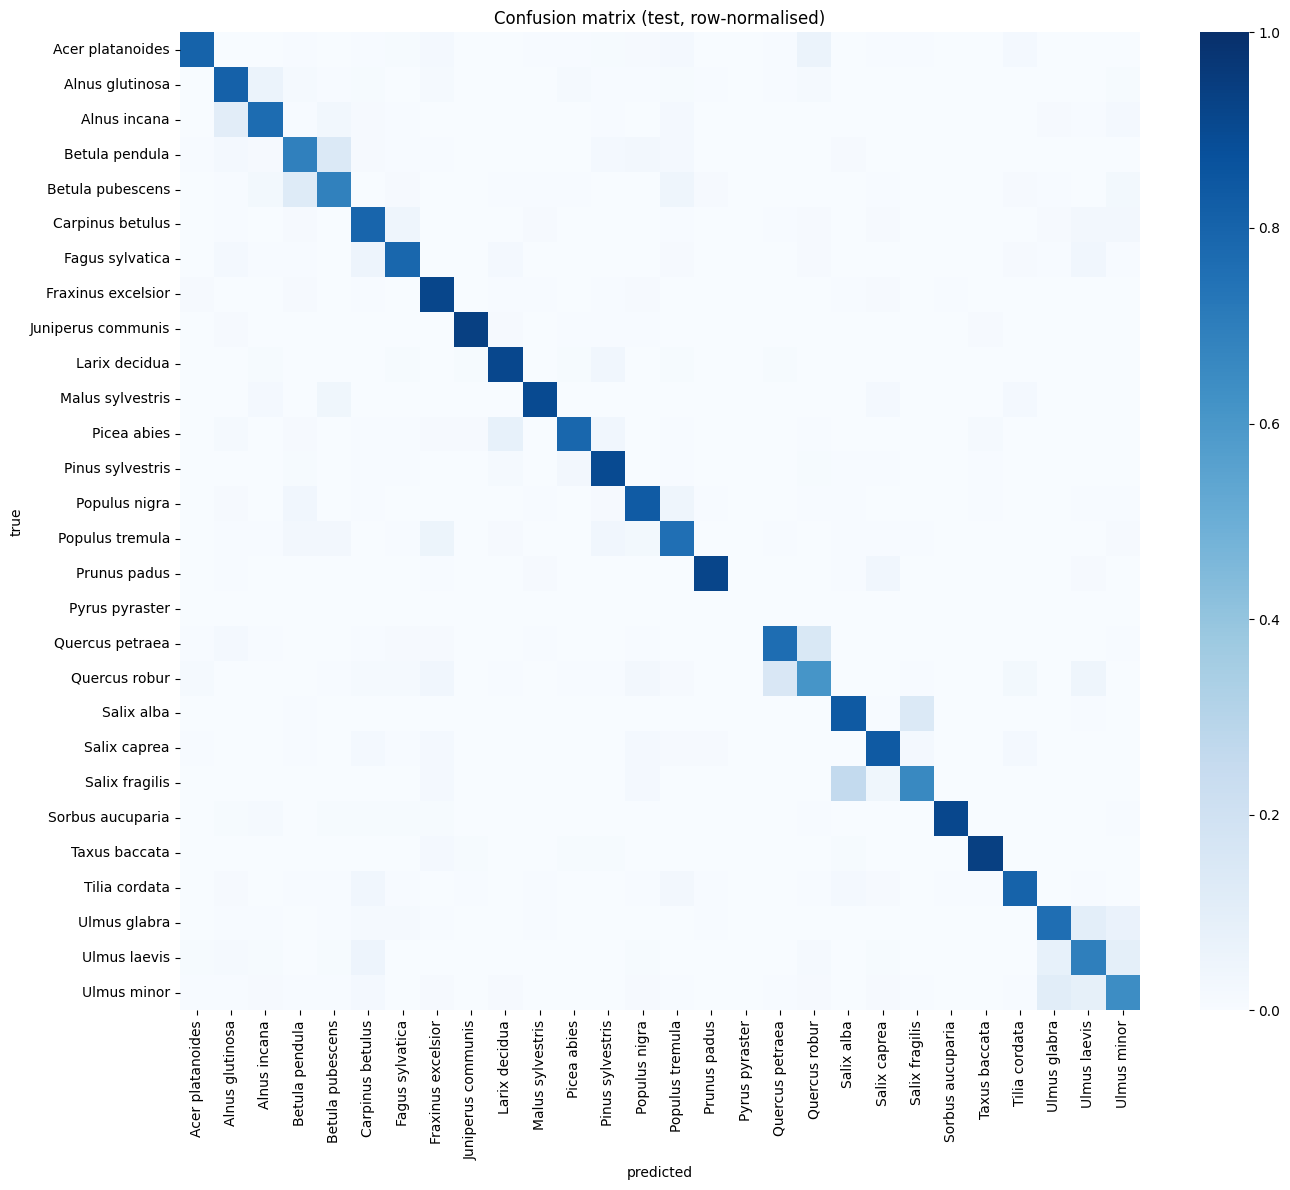


Most confused pairs (true -> predicted):
  0.26  Salix fragilis -> Salix alba
  0.15  Quercus robur -> Quercus petraea
  0.15  Quercus petraea -> Quercus robur
  0.14  Betula pendula -> Betula pubescens
  0.14  Salix alba -> Salix fragilis
  0.13  Betula pubescens -> Betula pendula
  0.11  Ulmus minor -> Ulmus glabra
  0.11  Alnus incana -> Alnus glutinosa


In [44]:
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

P = species_clf.predict_proba(X[test_idx])
classes_in_model = species_clf.classes_            # classes seen in training
full = np.zeros((len(test_idx), len(CLASSES))); full[:, classes_in_model] = P
pred = full.argmax(1); yt = y[test_idx]

top1 = (pred == yt).mean()
top3 = np.mean([yt[i] in np.argsort(-full[i])[:3] for i in range(len(yt))])
print(f'TEST top-1: {top1:.3f}   top-3: {top3:.3f}')

print('\nAccuracy per organ:')
for o in ORGANS:
    m = (df.organ.iloc[test_idx].values == o)
    if m.sum(): print(f'  {o:<11} n={m.sum():<5} top-1={np.mean(pred[m]==yt[m]):.3f}')

print('\nPer-species:')
print(classification_report(yt, pred, labels=range(len(CLASSES)), target_names=CLASSES, zero_division=0))

cm = confusion_matrix(yt, pred, labels=range(len(CLASSES)), normalize='true')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, xticklabels=CLASSES, yticklabels=CLASSES, cmap='Blues', vmin=0, vmax=1)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (test, row-normalised)')
plt.tight_layout(); plt.savefig(OUT_DIR / 'confusion_matrix.png', dpi=120); plt.show()

# most confused pairs
pairs = [(cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0.1]
print('\nMost confused pairs (true -> predicted):')
for v, a, b in sorted(pairs, reverse=True)[:15]: print(f'  {v:.2f}  {a} -> {b}')

# Tikrinimas

In [45]:
import pandas as pd
m = pd.read_csv(MANIFEST)
organs = ['leaf', 'bark', 'whole_tree', 'fruit']
t = m.groupby('species').agg(images=('file', 'count'),
                             labelled=('organ', lambda s: s.isin(organs).sum()))
print(t.reindex(sorted(SPECIES), fill_value=0).sort_values('images'))

                    images  labelled
species                             
Pyrus pyraster           0         0
Salix fragilis         387       337
Malus sylvestris       460       424
Betula pendula         955       788
Picea abies            955       786
Carpinus betulus      1040       960
Betula pubescens      1040       914
Acer platanoides      1040       959
Fraxinus excelsior    1040       893
Fagus sylvatica       1040       959
Larix decidua         1040       887
Juniperus communis    1040       813
Pinus sylvestris      1040       877
Populus nigra         1040       901
Alnus glutinosa       1040       916
Alnus incana          1040       939
Prunus padus          1040       922
Populus tremula       1040       908
Quercus robur         1040       948
Quercus petraea       1040       990
Salix alba            1040       886
Salix caprea          1040       928
Sorbus aucuparia      1040       950
Taxus baccata         1040       868
Tilia cordata         1040       956
U

In [1]:
import joblib
from pathlib import Path

OUT_DIR = Path('/content/drive/MyDrive/lt_trees/model_out')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save the two trained classifiers
joblib.dump(species_clf, OUT_DIR / 'species_clf.joblib')
joblib.dump(organ_clf,   OUT_DIR / 'organ_clf.joblib')

# 2. Save the class list + metadata the Streamlit app will need
import json
meta = {
    'classes': CLASSES,                 # list of 28 Latin names, fixed order
    'organs': ORGANS,                   # ['leaf','bark','whole_tree','fruit']
    'latin_to_lithuanian': SPECIES,     # your dict of common names
    'val_acc': float(val_acc),
    'best_C': int(bestC),
    'model_name': 'hf-hub:imageomics/bioclip',
}
with open(OUT_DIR / 'meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

# 3. Confirm
print('Saved files:')
for p in sorted(OUT_DIR.iterdir()):
    print(f'  {p.name:<25} {p.stat().st_size/1e6:6.2f} MB')

NameError: name 'species_clf' is not defined

In [3]:
from pathlib import Path
DATA_ROOT = Path('/content/drive/MyDrive/lt_trees')
MANIFEST  = DATA_ROOT / 'manifest.csv'
OUT_DIR   = DATA_ROOT / 'model_out'
print('manifest exists:', MANIFEST.exists())
print('features exist:', (OUT_DIR / 'features.npz').exists())

manifest exists: False
features exist: False


In [4]:
from pathlib import Path
import os

# Search for manifest.csv anywhere under MyDrive
for p in Path('/content/drive/MyDrive').rglob('manifest.csv'):
    print('FOUND:', p, '  size:', p.stat().st_size, 'bytes')

# List what's actually in lt_trees (if it exists)
root = Path('/content/drive/MyDrive/lt_trees')
print('\nlt_trees exists:', root.exists())
if root.exists():
    for p in sorted(root.iterdir()):
        print('  ', p.name, '(dir)' if p.is_dir() else f'({p.stat().st_size} bytes)')
    imgdir = root / 'images'
    if imgdir.exists():
        subdirs = [d for d in imgdir.iterdir() if d.is_dir()]
        print(f'\n  images/ has {len(subdirs)} species folders')
        for d in subdirs[:5]:
            n = len(list(d.glob('*.jpg')))
            print(f'    {d.name}: {n} jpgs')


lt_trees exists: True
   model_out (dir)


# Deepseek - editing

In [5]:
!pip -q install open_clip_torch scikit-learn pandas matplotlib seaborn pillow tqdm joblib requests

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
DATA_ROOT = Path('/content/drive/MyDrive/lt_trees')
MANIFEST  = DATA_ROOT / 'manifest.csv'
OUT_DIR   = DATA_ROOT / 'model_out'
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Data folder:', DATA_ROOT)

ValueError: Mountpoint must not already contain files

In [6]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

ValueError: Mountpoint must not already contain files

In [7]:
import shutil, os
if os.path.exists('/content/drive'):
    shutil.rmtree('/content/drive', ignore_errors=True)
    print('cleared /content/drive')
else:
    print('/content/drive did not exist')

cleared /content/drive


In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
from pathlib import Path
root = Path('/content/drive/MyDrive')
print('MyDrive visible:', root.exists())
print('lt_trees visible:', (root / 'lt_trees').exists())
print('first few items in MyDrive:')
for p in list(root.iterdir())[:5]:
    print('  ', p.name)


MyDrive visible: True
lt_trees visible: True
first few items in MyDrive:
   Colab Notebooks
   P1010357.MOV
   P1010359.MOV
   P1010324.MOV
   P1010358.MOV


In [13]:
%%writefile gbif_download.py

Overwriting gbif_download.py


In [14]:
import os
p = '/content/gbif_download.py'
print('exists:', os.path.exists(p))
print('size:', os.path.getsize(p) if os.path.exists(p) else 0, 'bytes')

exists: True
size: 1 bytes


In [16]:
!python gbif_download.py download --out /content/drive/MyDrive/lt_trees --target 50 --only "Picea abies" "Betula pendula"

In [17]:
from pathlib import Path
import pandas as pd

root = Path('/content/drive/MyDrive/lt_trees')
m = root / 'manifest.csv'
print('manifest exists:', m.exists())
if m.exists():
    df = pd.read_csv(m)
    print('rows in manifest:', len(df))
    print(df.species.value_counts().to_string())
    jpgs = list((root / 'images').rglob('*.jpg'))
    print('jpgs on disk:', len(jpgs))

manifest exists: True
rows in manifest: 26677
species
Pinus sylvestris      1040
Taxus baccata         1040
Juniperus communis    1040
Alnus incana          1040
Betula pubescens      1040
Larix decidua         1040
Alnus glutinosa       1040
Populus tremula       1040
Populus nigra         1040
Quercus petraea       1040
Quercus robur         1040
Ulmus laevis          1040
Ulmus minor           1040
Carpinus betulus      1040
Tilia cordata         1040
Acer platanoides      1040
Fraxinus excelsior    1040
Fagus sylvatica       1040
Ulmus glabra          1040
Salix alba            1040
Prunus padus          1040
Salix caprea          1040
Sorbus aucuparia      1040
Picea abies            955
Betula pendula         955
Malus sylvestris       460
Salix fragilis         387
jpgs on disk: 26677


cell H

In [20]:
import os
p = '/content/gbif_download.py'
print('size:', os.path.getsize(p), 'bytes')  # want ~12000-18000

size: 14765 bytes


In [22]:
from pathlib import Path
print('manifest:', Path('/content/drive/MyDrive/lt_trees/manifest.csv').exists())

manifest: True


In [24]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/lt_trees/manifest.csv')

print('columns:', list(df.columns))
print()
print('organ value counts:')
print(df.organ.value_counts())
print()
print('rows with organ_conf filled:', df.organ_conf.notna().sum(), '/', len(df))
print('organ_conf min/max/mean:',
      df.organ_conf.min(), df.organ_conf.max(), round(df.organ_conf.mean(), 3))
print()
print('labeled (organ != "unlabeled"):', int((df.organ != 'unlabeled').sum()), '/', len(df))
print()
print('sample rows:')
print(df[['species', 'organ', 'organ_conf']].head(5).to_string())

columns: ['file', 'species', 'organ', 'observer', 'license', 'source_url', 'occurrence_page', 'gbif_id', 'country', 'date', 'organ_conf']

organ value counts:
organ
leaf          13295
fruit          6263
whole_tree     3435
unlabeled      3132
bark            552
Name: count, dtype: int64

rows with organ_conf filled: 26677 / 26677
organ_conf min/max/mean: 0.2716738879680633 0.99905925989151 0.73

labeled (organ != "unlabeled"): 23545 / 26677

sample rows:
       species       organ  organ_conf
0  Picea abies  whole_tree    0.889855
1  Picea abies  whole_tree    0.946751
2  Picea abies  whole_tree    0.609049
3  Picea abies  whole_tree    0.647957
4  Picea abies       fruit    0.825426


Train - 2

**Cell B1**

In [26]:
SPECIES = {
 'Picea abies': 'Paprastoji eglė',
 'Pinus sylvestris': 'Paprastoji pušis',
 'Juniperus communis': 'Paprastasis kadagys',
 'Taxus baccata': 'Europinis kukmedis',
 'Larix decidua': 'Europinis maumedis',
 'Alnus glutinosa': 'Juodalksnis',
 'Alnus incana': 'Baltalksnis',
 'Betula pendula': 'Karpotasis beržas',
 'Betula pubescens': 'Plaukuotasis beržas',
 'Populus tremula': 'Drebulė',
 'Populus nigra': 'Juodoji tuopa',
 'Quercus robur': 'Paprastasis ąžuolas',
 'Quercus petraea': 'Bekotis ąžuolas',
 'Carpinus betulus': 'Paprastasis skroblas',
 'Tilia cordata': 'Mažalapė liepa',
 'Acer platanoides': 'Paprastasis klevas',
 'Fraxinus excelsior': 'Paprastasis uosis',
 'Fagus sylvatica': 'Paprastasis bukas',
 'Ulmus glabra': 'Kalninė guoba',
 'Ulmus laevis': 'Paprastoji vinkšna',
 'Ulmus minor': 'Paprastasis skirpstas',
 'Salix alba': 'Baltasis gluosnis',
 'Salix fragilis': 'Trapusis gluosnis',
 'Salix caprea': 'Blindė',
 'Sorbus aucuparia': 'Paprastasis šermukšnis',
 'Malus sylvestris': 'Miškinė obelis',
 'Pyrus pyraster': 'Miškinė kriaušė',
 'Prunus padus': 'Paprastoji ieva',
}
ORGANS = ['leaf', 'bark', 'whole_tree', 'fruit']
CLASSES = sorted(SPECIES)
cls2idx = {c: i for i, c in enumerate(CLASSES)}
DATA_ROOT = Path('/content/drive/MyDrive/lt_trees')
MANIFEST = DATA_ROOT / 'manifest.csv'
OUT_DIR = DATA_ROOT / 'model_out'
SEED = 42
print(len(CLASSES), 'species')

28 species


**Cell B2**

In [27]:
import pandas as pd
df = pd.read_csv(MANIFEST)
df = df[df.species.isin(CLASSES) & df.organ.isin(ORGANS)].copy()
df['observer'] = df['observer'].fillna('unknown').astype(str)
df['path'] = df['file'].apply(lambda f: str(DATA_ROOT / f))
df['y'] = df.species.map(cls2idx)
df['y_organ'] = df.organ.map({o: i for i, o in enumerate(ORGANS)})

before = len(df)
df = df[df.path.map(lambda p: Path(p).exists())].reset_index(drop=True)
print(f'kept {len(df)} of {before} rows (missing image files dropped)')
print(df.pivot_table(index='species', columns='organ', values='file', aggfunc='count', fill_value=0))

kept 23545 of 23545 rows (missing image files dropped)
organ               bark  fruit  leaf  whole_tree
species                                          
Acer platanoides      19    131   761          48
Alnus glutinosa       32    362   424          98
Alnus incana          16    309   572          42
Betula pendula        82    111   319         276
Betula pubescens      43    119   642         110
Carpinus betulus      38    193   616         113
Fagus sylvatica       16    129   659         155
Fraxinus excelsior    17    269   521          86
Juniperus communis     8    437   134         234
Larix decidua         15    404   223         245
Malus sylvestris       6    267   121          30
Picea abies           12    165   295         314
Pinus sylvestris      45    177   161         494
Populus nigra         36    159   490         216
Populus tremula       35    116   638         119
Prunus padus           4    555   337          26
Quercus petraea       10    220   702        

**Cell B3**

In [28]:
import torch, numpy as np, open_clip
from PIL import Image
from tqdm.auto import tqdm

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
model, _, preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip')
model = model.to(device).eval()

class DS(torch.utils.data.Dataset):
    def __init__(self, paths, flip=False): self.paths, self.flip = paths, flip
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            im = Image.open(self.paths[i]).convert('RGB')
        except Exception:
            im = Image.new('RGB', (224, 224))
            return preprocess(im), 0
        if self.flip: im = im.transpose(Image.FLIP_LEFT_RIGHT)
        return preprocess(im), 1

@torch.no_grad()
def embed(paths, flip=False, bs=64):
    dl = torch.utils.data.DataLoader(DS(paths, flip), batch_size=bs, num_workers=2)
    feats, ok = [], []
    for x, o in tqdm(dl):
        with torch.autocast(device, enabled=(device == 'cuda')):
            f = model.encode_image(x.to(device))
        feats.append(torch.nn.functional.normalize(f.float(), dim=-1).cpu()); ok.append(o)
    return torch.cat(feats).numpy(), torch.cat(ok).numpy().astype(bool)

CACHE = OUT_DIR / 'features.npz'
if CACHE.exists():
    z = np.load(CACHE, allow_pickle=True)
    if list(z['paths']) == list(df.path):
        X, X_flip, ok = z['X'], z['X_flip'], z['ok']
        print('loaded cached features')
    else:
        CACHE.unlink()
if not CACHE.exists():
    X, ok = embed(list(df.path))
    X_flip, _ = embed(list(df.path), flip=True)
    np.savez(CACHE, X=X, X_flip=X_flip, ok=ok, paths=np.array(df.path))

print('unreadable images:', int((~ok).sum()))
df, X, X_flip = df[ok].reset_index(drop=True), X[ok], X_flip[ok]
print('final:', len(df), 'images,', X.shape[1], 'dim features')

device: cuda


open_clip_config.json:   0%|          | 0.00/469 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

loaded cached features
unreadable images: 0
final: 23545 images, 512 dim features


**Cell B4**

In [29]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss.split(X, df.y, groups=df.observer))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15/0.85, random_state=SEED)
tr_rel, va_rel = next(gss2.split(X[trainval_idx], df.y.iloc[trainval_idx], groups=df.observer.iloc[trainval_idx]))
train_idx, val_idx = trainval_idx[tr_rel], trainval_idx[va_rel]
print('train/val/test:', len(train_idx), len(val_idx), len(test_idx))

train/val/test: 16489 3239 3817


**Cell B5**

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y = df.y.values
Xtr = np.concatenate([X[train_idx], X_flip[train_idx]])
ytr = np.concatenate([y[train_idx], y[train_idx]])

best = None
for C in [1, 3, 10, 30, 100]:
    clf = LogisticRegression(C=C, max_iter=2000, class_weight='balanced')
    clf.fit(Xtr, ytr)
    acc = accuracy_score(y[val_idx], clf.predict(X[val_idx]))
    print(f'C={C:<4} val acc={acc:.3f}')
    if best is None or acc > best[0]: best = (acc, C, clf)
val_acc, bestC, species_clf = best
print('best C:', bestC, ' val acc:', round(val_acc, 3))

yo = df.y_organ.values
organ_clf = LogisticRegression(C=10, max_iter=2000, class_weight='balanced')
organ_clf.fit(np.concatenate([X[train_idx], X_flip[train_idx]]),
              np.concatenate([yo[train_idx], yo[train_idx]]))
print('organ val acc:',
      round(accuracy_score(yo[val_idx], organ_clf.predict(X[val_idx])), 3))

C=1    val acc=0.808
C=3    val acc=0.809
C=10   val acc=0.799
C=30   val acc=0.786
C=100  val acc=0.775
best C: 3  val acc: 0.809
organ val acc: 0.881


**Cell B6**

In [31]:
import joblib, json
OUT_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(species_clf, OUT_DIR / 'species_clf.joblib')
joblib.dump(organ_clf,   OUT_DIR / 'organ_clf.joblib')

meta = {
    'classes': CLASSES,
    'organs': ORGANS,
    'latin_to_lithuanian': SPECIES,
    'val_acc': float(val_acc),
    'best_C': int(bestC),
    'model_name': 'hf-hub:imageomics/bioclip',
}
with open(OUT_DIR / 'meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print('Saved:')
for p in sorted(OUT_DIR.iterdir()):
    print(f'  {p.name:<25} {p.stat().st_size/1e6:6.2f} MB')

Saved:
  config.json                 0.00 MB
  confusion_matrix.png        0.16 MB
  features.npz               98.18 MB
  meta.json                   0.00 MB
  organ_clf.joblib            0.02 MB
  species_clf.joblib          0.11 MB
